In [3]:
!pip install -q torch torchvision numpy pandas matplotlib psutil

In [4]:
import os
import sys
import time
import json
import subprocess
import platform
import random

import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil

from pathlib import Path
from datetime import datetime
from IPython.display import display

print("All libraries imported successfully!")
print("Python Version:", sys.version)
print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)
print("NumPy Version:", np.__version__)

All libraries imported successfully!
Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch Version: 2.14.1+cu130
Torchvision Version: 0.29.1+cu130
NumPy Version: 2.4.6


In [5]:
PROJECT_DIR = "/content/VisionPort_Skill4"

os.makedirs(PROJECT_DIR, exist_ok=True)

folders = [
    "data",
    "models",
    "src",
    "notebooks",
    "tests",
    "configs",
    "outputs"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("PROJECT REPOSITORY CREATED")
print("=" * 40)

for root, dirs, files_list in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    indent = " " * 4 * level
    print(indent + os.path.basename(root) + "/")

PROJECT REPOSITORY CREATED
VisionPort_Skill4/
    tests/
    models/
    notebooks/
    data/
    outputs/
    src/
    configs/


In [6]:
files_content = {
    "README.md": """
# VisionPort Project

Project Repository and PyTorch-CUDA Development Environment.

Modules:
- PyTorch Model Development
- GPU Acceleration
- Git Version Control
- Environment Configuration
- Performance Testing
""",

    "requirements.txt": """
torch
torchvision
numpy
pandas
matplotlib
psutil
""",

    "src/main.py": """
import torch

print("VisionPort Application Started")
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
""",

    "configs/config.json": json.dumps({
        "project": "VisionPort",
        "model": "ResNet18",
        "framework": "PyTorch",
        "device": "auto"
    }, indent=4),

    "tests/test_environment.py": """
import torch

def test_torch():
    assert torch.__version__ is not None

def test_tensor():
    x = torch.tensor([1, 2, 3])
    assert x.sum().item() == 6
""",

    ".gitignore": """
__pycache__/
*.pyc
.env
venv/
.ipynb_checkpoints/
models/*.pt
"""
}

for filename, content in files_content.items():
    path = os.path.join(PROJECT_DIR, filename)

    with open(path, "w") as f:
        f.write(content.strip() + "\n")

print("Project files created successfully!")

for filename in files_content:
    print("✓", filename)

Project files created successfully!
✓ README.md
✓ requirements.txt
✓ src/main.py
✓ configs/config.json
✓ tests/test_environment.py
✓ .gitignore


In [7]:
os.chdir(PROJECT_DIR)

def run_git(command):
    result = subprocess.run(
        ["git"] + command,
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)

    return result

run_git(["init", "-b", "main"])

run_git(["config", "user.name", "VisionPort Student"])
run_git(["config", "user.email", "student@example.com"])

run_git(["add", "."])

run_git([
    "commit",
    "-m",
    "Initial VisionPort project setup"
])

print("Git repository initialized successfully!")

Initialized empty Git repository in /content/VisionPort_Skill4/.git/




[main (root-commit) 5e62ed0] Initial VisionPort project setup
 6 files changed, 41 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 configs/config.json
 create mode 100644 requirements.txt
 create mode 100644 src/main.py
 create mode 100644 tests/test_environment.py

Git repository initialized successfully!


In [8]:
# Create a development branch
run_git(["branch", "development"])

# Switch to development branch
run_git(["switch", "development"])

# Add a new project file
new_file = os.path.join(PROJECT_DIR, "src", "gpu_test.py")

with open(new_file, "w") as f:
    f.write("""
import torch

print("GPU Test Module")
print("CUDA Available:", torch.cuda.is_available())
""")

# Stage and commit changes
run_git(["add", "."])

run_git([
    "commit",
    "-m",
    "Added GPU testing module"
])

# Display current branch
run_git(["branch", "--show-current"])

# Display commit history
run_git(["log", "--oneline", "--all"])

# Display repository status
run_git(["status"])




[development 6a530fc] Added GPU testing module
 1 file changed, 5 insertions(+)
 create mode 100644 src/gpu_test.py

development

6a530fc Added GPU testing module
5e62ed0 Initial VisionPort project setup

On branch development
nothing to commit, working tree clean



CompletedProcess(args=['git', 'status'], returncode=0, stdout='On branch development\nnothing to commit, working tree clean\n', stderr='')

In [9]:
print("=" * 50)
print("PYTORCH DEVELOPMENT ENVIRONMENT")
print("=" * 50)

print("Python Version:", platform.python_version())
print("Operating System:", platform.system())
print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)
print("NumPy Version:", np.__version__)

print("\nEnvironment Status:")

print("PyTorch Installed: SUCCESS")
print("Tensor Operations: READY")

if torch.cuda.is_available():
    print("CUDA Available: YES")
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
else:
    print("CUDA Available: NO")
    print("Running with CPU fallback")

PYTORCH DEVELOPMENT ENVIRONMENT
Python Version: 3.13.16
Operating System: Linux
PyTorch Version: 2.14.1+cu130
Torchvision Version: 0.29.1+cu130
NumPy Version: 2.4.6

Environment Status:
PyTorch Installed: SUCCESS
Tensor Operations: READY
CUDA Available: YES
GPU Name: Tesla T4
CUDA Version: 13.0


In [10]:
print("=" * 50)
print("CUDA AND GPU VERIFICATION")
print("=" * 50)

cuda_available = torch.cuda.is_available()

if cuda_available:

    device = torch.device("cuda:0")

    print("CUDA Status: AVAILABLE")
    print("GPU Device:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)

    properties = torch.cuda.get_device_properties(0)

    total_memory = properties.total_memory / (1024**3)

    print("GPU Memory:", round(total_memory, 2), "GB")
    print("GPU Multiprocessors:", properties.multi_processor_count)

else:

    device = torch.device("cpu")

    print("CUDA Status: NOT AVAILABLE")
    print("Using CPU instead.")

print("Selected Device:", device)

CUDA AND GPU VERIFICATION
CUDA Status: AVAILABLE
GPU Device: Tesla T4
CUDA Version: 13.0
GPU Memory: 14.56 GB
GPU Multiprocessors: 40
Selected Device: cuda:0


In [11]:
print("=" * 50)
print("TENSOR COMPUTATION TEST")
print("=" * 50)

torch.manual_seed(42)

A = torch.randn(1000, 1000, device=device)
B = torch.randn(1000, 1000, device=device)

C = torch.matmul(A, B)

print("Tensor A Shape:", A.shape)
print("Tensor B Shape:", B.shape)
print("Output Tensor Shape:", C.shape)
print("Tensor Device:", C.device)

print("Matrix Multiplication: SUCCESS")

print("\nSample Output:")
print(C[:5, :5].cpu())

TENSOR COMPUTATION TEST
Tensor A Shape: torch.Size([1000, 1000])
Tensor B Shape: torch.Size([1000, 1000])
Output Tensor Shape: torch.Size([1000, 1000])
Tensor Device: cuda:0
Matrix Multiplication: SUCCESS

Sample Output:
tensor([[-39.9894,  14.1536,  27.8719,  22.3708, -43.7370],
        [  9.5871, -25.6739,  14.3366,  39.0869, -28.3433],
        [  5.8170,  22.3123, -52.4290, -31.8623,   6.8241],
        [-24.5277,  22.6703,   8.8741,  13.6629,  44.0928],
        [-20.9517, -27.9388,  83.9953, -15.5771,  -6.4091]])


In [12]:
sizes = [250, 500, 750, 1000, 1500, 2000]

cpu_times = []
gpu_times = []

for size in sizes:

    a_cpu = torch.randn(size, size)
    b_cpu = torch.randn(size, size)

    # CPU benchmark
    start = time.perf_counter()

    for _ in range(3):
        result = torch.matmul(a_cpu, b_cpu)

    cpu_time = (time.perf_counter() - start) / 3

    cpu_times.append(cpu_time)

    # GPU benchmark if available
    if cuda_available:

        a_gpu = a_cpu.to(device)
        b_gpu = b_cpu.to(device)

        torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(3):
            result_gpu = torch.matmul(a_gpu, b_gpu)

        torch.cuda.synchronize()

        gpu_time = (time.perf_counter() - start) / 3

        gpu_times.append(gpu_time)

    else:
        gpu_times.append(np.nan)

    print(
        f"Matrix Size: {size} | "
        f"CPU: {cpu_time:.5f}s | "
        f"GPU: {gpu_times[-1]:.5f}s"
        if cuda_available else
        f"Matrix Size: {size} | CPU: {cpu_time:.5f}s | GPU: Not available"
    )

print("\nPerformance Testing Completed!")

Matrix Size: 250 | CPU: 0.01040s | GPU: 0.01316s
Matrix Size: 500 | CPU: 0.00300s | GPU: 0.00020s
Matrix Size: 750 | CPU: 0.00907s | GPU: 0.00039s
Matrix Size: 1000 | CPU: 0.01583s | GPU: 0.00081s
Matrix Size: 1500 | CPU: 0.05536s | GPU: 0.00261s
Matrix Size: 2000 | CPU: 0.19999s | GPU: 0.00593s

Performance Testing Completed!


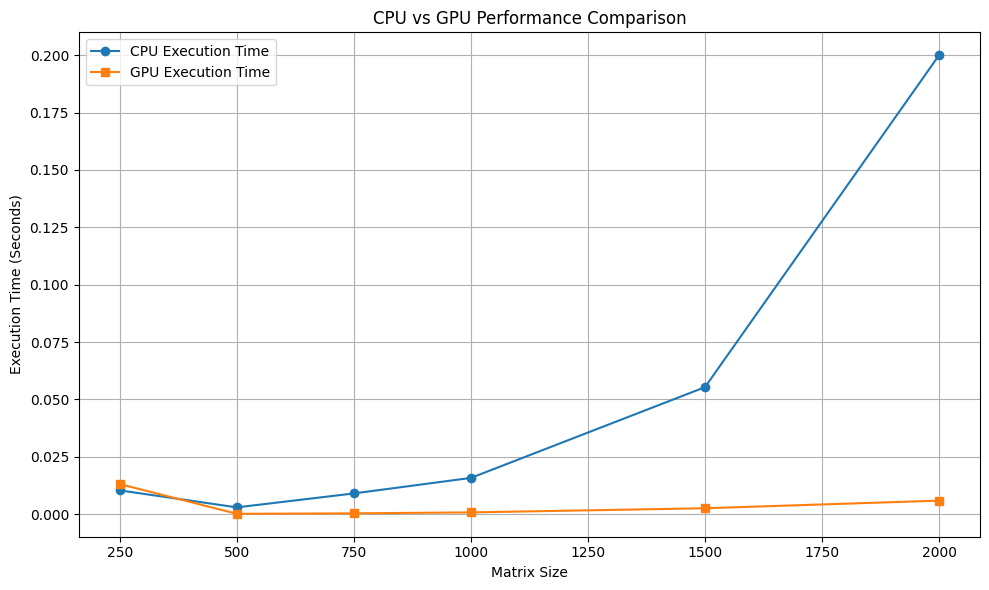

In [13]:
plt.figure(figsize=(10, 6))

plt.plot(
    sizes,
    cpu_times,
    marker="o",
    label="CPU Execution Time"
)

if cuda_available:
    plt.plot(
        sizes,
        gpu_times,
        marker="s",
        label="GPU Execution Time"
    )

plt.title("CPU vs GPU Performance Comparison")
plt.xlabel("Matrix Size")
plt.ylabel("Execution Time (Seconds)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

,Memory Type,Memory (GB)
0,Allocated,0.065
1,Reserved,0.074
2,Free (estimated),14.489


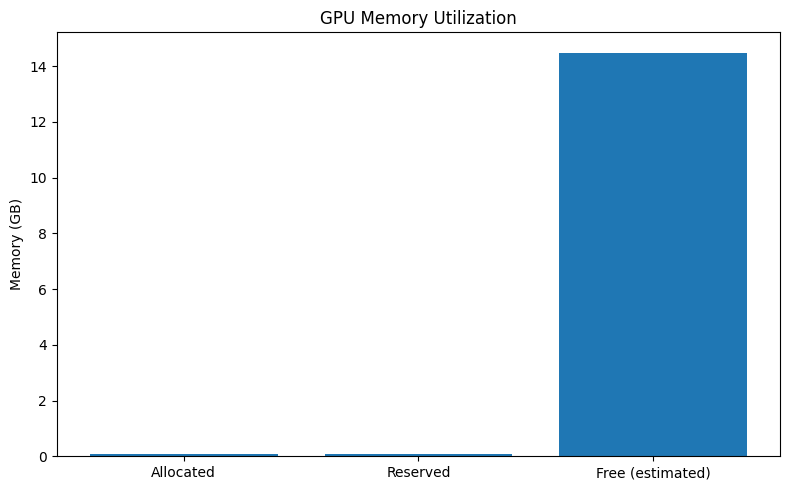

In [14]:
if cuda_available:

    torch.cuda.empty_cache()

    total_memory = torch.cuda.get_device_properties(0).total_memory

    allocated = torch.cuda.memory_allocated(0)
    reserved = torch.cuda.memory_reserved(0)

    free_memory = total_memory - reserved

    memory_data = {
        "Memory Type": [
            "Allocated",
            "Reserved",
            "Free (estimated)"
        ],
        "Memory (GB)": [
            allocated / 1024**3,
            reserved / 1024**3,
            free_memory / 1024**3
        ]
    }

    memory_df = pd.DataFrame(memory_data)

    display(memory_df.round(3))

    plt.figure(figsize=(8, 5))

    plt.bar(
        memory_df["Memory Type"],
        memory_df["Memory (GB)"]
    )

    plt.title("GPU Memory Utilization")
    plt.ylabel("Memory (GB)")
    plt.tight_layout()
    plt.show()

else:
    print("GPU memory monitoring requires a CUDA-enabled GPU.")

In [16]:
print("=" * 50)
print("FINAL GIT REPOSITORY STATUS")
print("=" * 50)

# Display Git status
run_git(["status", "--short"])

# Display branches
run_git(["branch", "-a"])

# Display commit history
run_git(["log", "--oneline", "--all"])

print("\nPROJECT FILES")

for root, dirs, files_list in os.walk(PROJECT_DIR):

    dirs[:] = [d for d in dirs if d != ".git"]

    for filename in files_list:
        print(
            os.path.relpath(
                os.path.join(root, filename),
                PROJECT_DIR
            )
        )

print("\nStep 12 Completed Successfully!")

FINAL GIT REPOSITORY STATUS

* development
  main

6a530fc Added GPU testing module
5e62ed0 Initial VisionPort project setup


PROJECT FILES
requirements.txt
README.md
.gitignore
tests/test_environment.py
src/main.py
src/gpu_test.py
configs/config.json

Step 12 Completed Successfully!


In [17]:
report = {
    "Practical": "Skill 4",
    "Topic": "Project Repository, Git Workflow and PyTorch-CUDA Development Environment Setup",
    "Date": str(datetime.now()),
    "Python Version": platform.python_version(),
    "PyTorch Version": torch.__version__,
    "Torchvision Version": torchvision.__version__,
    "CUDA Available": cuda_available,
    "Selected Device": str(device),
    "GPU Name": (
        torch.cuda.get_device_name(0)
        if cuda_available else "Not Available"
    ),
    "Git Repository": "Initialized",
    "Git Branch": "development",
    "Git Workflow": "Completed",
    "Tensor Computation": "Successful",
    "CPU Benchmark": "Completed",
    "GPU Benchmark": "Completed" if cuda_available else "Skipped - CPU fallback"
}

print("FINAL SKILL 4 REPORT")
print("=" * 50)

for key, value in report.items():
    print(f"{key}: {value}")

with open(
    os.path.join(PROJECT_DIR, "outputs", "skill4_report.json"),
    "w"
) as f:
    json.dump(report, f, indent=4)

print("\nReport saved successfully!")

FINAL SKILL 4 REPORT
Practical: Skill 4
Topic: Project Repository, Git Workflow and PyTorch-CUDA Development Environment Setup
Date: 2026-11-17 03:18:48.854829
Python Version: 3.13.16
PyTorch Version: 2.14.1+cu130
Torchvision Version: 0.29.1+cu130
CUDA Available: True
Selected Device: cuda:0
GPU Name: Tesla T4
Git Repository: Initialized
Git Branch: development
Git Workflow: Completed
Tensor Computation: Successful
CPU Benchmark: Completed
GPU Benchmark: Completed

Report saved successfully!


In [18]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/VisionPort_Skill4",
    "zip",
    PROJECT_DIR
)

files.download("/content/VisionPort_Skill4.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>